# 01 – Exploring the 2024 games and betting lines

**Goal:** understand the raw CollegeFootballData (CFBD) data before building the clean games
table in Phase 1. This notebook looks at one season (2024) and answers:

1. Which columns are available, and which are safe to use for prediction?
2. How do neutral-site games appear?
3. How do FCS opponents appear?
4. How is the betting spread signed?

**API cost:** two calls in total (one for games, one for lines), made only the first time.
`football_model.data` saves each response to `data/raw/` as Parquet, so re-running this
notebook reads the cached files and costs nothing. Each load prints which happened.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from football_model import data

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEASON = 2024

## 1. Games: what columns do we get?

`load_games` asks for every game involving an FBS team, regular season and postseason
together. The columns are exactly what CFBD returns (camelCase). Renaming to our
`snake_case` convention happens later in `clean.py`.

In [2]:
games = data.load_games(SEASON)
print(games.shape)
games.dtypes

Loaded from cache: games_2024.parquet
(920, 34)


id                              int64
season                          int64
week                            int64
seasonType                        str
startDate                         str
startTimeTBD                     bool
completed                        bool
neutralSite                      bool
conferenceGame                   bool
attendance                    float64
venueId                         int64
venue                             str
homeId                          int64
homeTeam                          str
homeConference                    str
homeClassification                str
homePoints                    float64
homeLineScores                 object
homePostgameWinProbability    float64
homePregameElo                  int64
homePostgameElo               float64
awayId                          int64
awayTeam                          str
awayConference                    str
awayClassification                str
awayPoints                    float64
awayLineScor

In [3]:
games.head(3).T

,0,1,2
id,401635525,401643697,401643696
season,2024,2024,2024
week,1,1,1
seasonType,regular,regular,regular
startDate,2024-08-24T16:00:00+00:00,2024-08-24T20:00:00+00:00,2024-08-25T00:00:00+00:00
startTimeTBD,False,False,False
completed,True,True,True
neutralSite,True,False,False
conferenceGame,True,False,False
attendance,47998.0,17314.0,20263.0


### Sorting the columns by when they are known

The most important question about any column is **whether it is known before kickoff.**
A column that is only known afterward would leak the outcome into the model. This is
like putting a post-treatment variable on the right-hand side of a regression: the fit
looks great, but you can't use it to forecast.

| Role | Columns | Usable as a model input? |
| --- | --- | --- |
| Keys | `id`, `season`, `week`, `seasonType`, `startDate` | Keys only |
| Teams and context | `homeTeam`, `awayTeam`, `homeId`/`awayId`, conferences, classifications, `neutralSite`, `conferenceGame`, `venue`, `venueId` | Yes, known in advance |
| **Outcome** | `homePoints`, `awayPoints` | Only as the target (`margin`) |
| **Post-game (leak)** | `homeLineScores`/`awayLineScores` (points by quarter), `homePostgameWinProbability`, `homePostgameElo`, `excitementIndex`, `attendance`, `highlights` | **Never** |
| CFBD's own rating | `homePregameElo`, `awayPregameElo` | Known pregame, but it's someone else's model. Use it as a comparison, not as a feature. |
| Status / extras | `completed`, `startTimeTBD`, `notes` (bowl or event name), `playoff` (CFP round and seeds) | Bookkeeping |

`clean.py` should drop the post-game columns completely, so they can't slip into a feature
set by accident.

## 2. Season structure

Things to check: regular vs. postseason counts, how weeks are numbered, and whether any
game is unfinished.

In [4]:
games.groupby("seasonType")["week"].agg(["count", "min", "max"])

,count,min,max
seasonType,,,
postseason,46,1,1
regular,874,1,16


In [5]:
games[~games["completed"]][["id", "week", "homeTeam", "awayTeam", "startDate", "homePoints"]]

,id,week,homeTeam,awayTeam,startDate,homePoints
331,401640992,5,App State,Liberty,2024-09-28T19:30:00+00:00,NaN


In [6]:
# startDate is an ISO string with a UTC offset. Convert to a real timestamp.
start = pd.to_datetime(games["startDate"], utc=True)
print(start.dtype)
print(start.min(), "->", start.max())

datetime64[us, UTC]
2024-08-24 16:00:00+00:00 -> 2025-01-21 00:30:00+00:00


**What matters here**

- **Every postseason game is labeled `week = 1`.** Week alone can't order games in time.
  Sort by `startDate` (or by `seasonType` then `week`). This matters for walk-forward
  validation and for Elo, which must process games in the order they were played.
- **One game never finished:** App State vs. Liberty (week 5) was cancelled because of
  Hurricane Helene. It has no score, so `clean.py` must drop rows where `completed` is
  False or the points are missing. Do this explicitly; a silent `NaN` margin can quietly
  break a regression.
- `startDate` comes back as an ISO string with a UTC offset. Store it as a timezone-aware
  UTC timestamp (as CLAUDE.md requires) so "games before this kickoff" comparisons are exact.

## 3. Neutral-site games

In [7]:
pd.crosstab(games["seasonType"], games["neutralSite"], margins=True)

neutralSite,False,True,All
seasonType,,,
postseason,5,41,46
regular,835,39,874
All,840,80,920


In [8]:
neutral_cols = ["week", "seasonType", "homeTeam", "awayTeam", "venue", "notes"]
games[games["neutralSite"] & (games["seasonType"] == "regular")][neutral_cols].head(15)

,week,seasonType,homeTeam,awayTeam,venue,notes
0,1,regular,Georgia Tech,Florida State,Aviva Stadium,Aer Lingus College Football Classic
12,1,regular,Arkansas,Arkansas-Pine Bluff,War Memorial Stadium (AR),NaN
19,1,regular,Kansas,Lindenwood,Children's Mercy Park,NaN
33,1,regular,Georgia,Clemson,Mercedes-Benz Stadium,Aflac Kickoff
48,1,regular,Northwestern,Miami (OH),Lanny and Sharon Martin Stadium,NaN
98,1,regular,LSU,USC,Allegiant Stadium,Modelo Vegas Kickoff Classic
102,2,regular,Northwestern,Duke,Lanny and Sharon Martin Stadium,NaN
139,2,regular,Florida International,Central Michigan,Pitbull Stadium,NaN
161,2,regular,NC State,Tennessee,Bank of America Stadium,Duke’s Mayo Classic
180,3,regular,Kansas,UNLV,Children's Mercy Park,NaN


In [9]:
# Postseason games that are NOT neutral: the CFP first round is played on campus.
games[~games["neutralSite"] & (games["seasonType"] == "postseason")][neutral_cols]

,week,seasonType,homeTeam,awayTeam,venue,notes
881,1,postseason,Notre Dame,Indiana,Notre Dame Stadium,College Football Playoff First Round Game Pres...
882,1,postseason,Penn State,SMU,Beaver Stadium,College Football Playoff First Round Game Pres...
883,1,postseason,Texas,Clemson,DKR-Texas Memorial Stadium,College Football Playoff First Round Game Pres...
884,1,postseason,Ohio State,Tennessee,Ohio Stadium,College Football Playoff First Round Game Pres...
885,1,postseason,UTSA,Coastal Carolina,Brooks Stadium (SC),Myrtle Beach Bowl


**What matters here**

- Neutral games still have a "home" and an "away" team, because CFBD has to list one team
  first. We keep CFBD's home team, so `margin` keeps the same home-minus-away meaning, and
  the model sets **home-field advantage to zero** for these rows. In a regression, the
  `home` indicator is 1 for true home games and 0 for neutral ones.
- Most bowls are neutral, but **CFP first-round games are true home games** for the
  higher seed. Don't assume postseason means neutral; trust the flag.
- **The flag isn't perfect.** Some games marked neutral are effectively home games at a
  temporary stadium: Northwestern played at Lanny and Sharon Martin Stadium during its
  stadium rebuild, and Kansas played at Children's Mercy Park during its renovation. Those
  teams probably kept part of their home edge. It's a small number of games, so accept the
  flag for now. A later phase could test a "partial home" correction if residuals suggest it.
- The `notes` text sometimes has broken characters (`Dukeâ€™s` instead of `Duke's`). This
  is an encoding problem in the source data. It's cosmetic, but don't join on `notes`.

## 4. FCS opponents

In [10]:
pd.crosstab(games["homeClassification"], games["awayClassification"], margins=True)

awayClassification,fbs,fcs,All
homeClassification,,,
fbs,799,121,920
All,799,121,920


In [11]:
fcs_teams = games.loc[games["awayClassification"] == "fcs", "awayTeam"]
print("FBS-vs-FCS games:", len(fcs_teams))
print("Distinct FCS teams:", fcs_teams.nunique())
print("Games per FCS team:")
fcs_teams.value_counts().value_counts().sort_index()

FBS-vs-FCS games: 121
Distinct FCS teams: 96
Games per FCS team:


count
1    71
2    25
Name: count, dtype: int64

In [12]:
# Does CFBD's own Elo cover FCS teams?
games.loc[games["awayClassification"] == "fcs", ["awayTeam", "awayPregameElo"]].head()

,awayTeam,awayPregameElo
1,Montana State,NaN
3,Delaware State,NaN
4,Howard,NaN
5,New Hampshire,NaN
6,North Carolina A&T,NaN


**What matters here**

- FCS teams show up through `homeClassification` / `awayClassification == "fcs"`. In this
  pull, **every FCS team is the away team**. FBS teams almost never visit FCS stadiums. The
  `fbs` filter may also leave out the rare games an FCS team hosts, so watch for this when
  pulling other seasons.
- There are 121 such games against **96 different FCS teams, and each FCS team appears only
  once or twice.** With a team dummy for each one, every FCS coefficient would rest on one
  or two observations. That's the textbook case of an unidentified or high-variance
  parameter. Ridge would shrink them heavily anyway, but lumping them all into a single team
  `"FCS"` gives one well-estimated coefficient from 121 games. That's the CLAUDE.md rule.
- CFBD's pregame Elo is **missing for every FCS team**. One more reason not to rely on it.

## 5. The target: home margin

`margin = homePoints - awayPoints`. Positive means the home team won.

In [13]:
games_done = games[games["completed"]].copy()
games_done["margin"] = games_done["homePoints"] - games_done["awayPoints"]

is_fbs_game = (games_done["homeClassification"] == "fbs") & (
    games_done["awayClassification"] == "fbs"
)
games_done["matchup"] = np.where(is_fbs_game, "FBS vs FBS", "FBS vs FCS")

print("Ties:", (games_done["margin"] == 0).sum())
games_done.groupby(["matchup", "neutralSite"])["margin"].agg(["count", "mean", "std"]).round(1)

Ties: 0


count  mean   std
matchup    neutralSite                   
FBS vs FBS False          722   5.4  20.3
           True            76  -1.2  16.9
FBS vs FCS False          117  31.0  18.7
           True             4  34.0  31.0

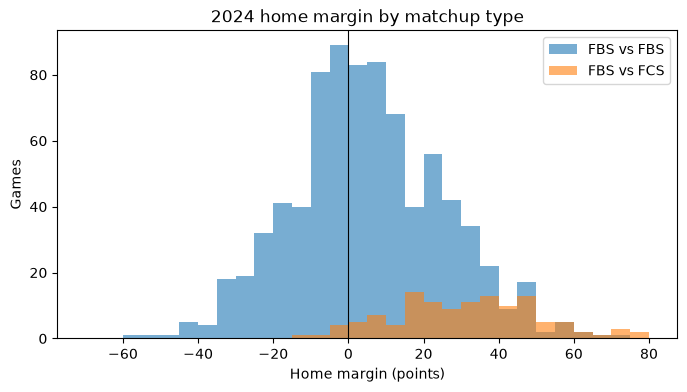

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(-70, 85, 5)
for label, group in games_done.groupby("matchup"):
    ax.hist(group["margin"], bins=bins, alpha=0.6, label=label)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Home margin (points)")
ax.set_ylabel("Games")
ax.set_title(f"{SEASON} home margin by matchup type")
ax.legend()
plt.show()

**What matters here**

- **No ties.** Overtime always produces a winner, so `home_win = margin > 0` is a clean
  binary outcome.
- **A first look at home-field advantage:** FBS home teams at non-neutral sites won by about
  5.4 points on average, against about −1 at neutral sites. This raw difference mixes
  home edge with schedule effects (good teams host weaker teams more often). The Phase 3
  regression, which controls for both teams' strength, estimates home field properly. Expect
  a value of a few points.
- **FBS-vs-FCS games average a 31-point margin with a wide spread.** These blowouts say
  little about how good the FBS team is, and they can pull a least-squares fit around
  (residuals are large and, under squared loss, those rows carry a lot of weight). That
  supports one shared FCS team now, and testing a margin cap in Phase 3.
- The margin has a fat-tailed, roughly bell-shaped distribution with a standard deviation
  of about 17–20 points. That's the σ that turns a spread into a win probability in Phase 4.

## 6. Betting lines

`load_lines` returns **one row per game per sportsbook** (`provider`). The API nests the
books inside each game; `data.flatten_lines` only expands that nesting into rows.

In [15]:
lines = data.load_lines(SEASON)
print(lines.shape)
lines.dtypes

Loaded from cache: lines_2024.parquet
(3172, 23)


id                      int64
season                  int64
seasonType                str
week                    int64
startDate                 str
homeTeamId              int64
homeTeam                  str
homeConference            str
homeClassification        str
homeScore               int64
awayTeamId              int64
awayTeam                  str
awayConference            str
awayClassification        str
awayScore               int64
provider                  str
spread                float64
formattedSpread           str
spreadOpen            float64
overUnder             float64
homeMoneyline         float64
awayMoneyline         float64
overUnderOpen         float64
dtype: object

In [16]:
line_cols = ["id", "homeTeam", "awayTeam", "provider", "spread", "formattedSpread",
             "spreadOpen", "overUnder", "homeMoneyline", "awayMoneyline"]
lines[line_cols].head(9)

,id,homeTeam,awayTeam,provider,spread,formattedSpread,spreadOpen,overUnder,homeMoneyline,awayMoneyline
0,401635575,Pittsburgh,California,DraftKings,-3.5,Pittsburgh -3.5,-2.5,57.5,-166.0,140.0
1,401635575,Pittsburgh,California,Bovada,-3.5,Pittsburgh -3.5,-4.5,57.5,-170.0,145.0
2,401635575,Pittsburgh,California,ESPN Bet,-3.5,Pittsburgh -3.5,-3.5,56.5,-170.0,145.0
3,401654609,Robert Morris,Merrimack,ESPN Bet,1.5,Merrimack -1.5,NaN,48.5,NaN,NaN
4,401643828,UL Monroe,Texas State,Bovada,9.5,Texas State -9.5,7.0,50.0,240.0,-290.0
5,401643828,UL Monroe,Texas State,ESPN Bet,9.5,Texas State -9.5,7.0,49.5,300.0,-400.0
6,401643828,UL Monroe,Texas State,DraftKings,9.5,Texas State -9.5,8.5,50.0,280.0,-355.0
7,401628444,Clemson,South Carolina,DraftKings,-3.0,Clemson -3,-4.5,49.5,-142.0,120.0
8,401628444,Clemson,South Carolina,Bovada,-2.5,Clemson -2.5,-2.5,49.0,-135.0,115.0


In [17]:
print("Rows per provider:")
print(lines["provider"].value_counts(), "\n")
print("Number of providers per game:")
print(lines.groupby("id")["provider"].nunique().value_counts().sort_index())

Rows per provider:
provider
ESPN Bet      1551
DraftKings     817
Bovada         804
Name: count, dtype: int64 

Number of providers per game:
provider
1    726
2     47
3    784
Name: count, dtype: int64


In [18]:
# Coverage by week (postseason shown as 'post')
week_label = lines["week"].astype(str).where(lines["seasonType"] == "regular", "post")
pd.crosstab(lines["provider"], week_label)[[*map(str, range(1, 17)), "post"]]

week,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,post
provider,,,,,,,,,,,,,,,,,
Bovada,43,49,52,54,52,49,52,59,56,48,50,53,62,67,9,2,47
DraftKings,43,51,58,61,54,48,51,58,56,49,49,54,64,66,9,1,45
ESPN Bet,104,109,104,101,103,102,104,109,114,103,109,115,125,77,17,5,50


**What matters here**

- There are three providers: **ESPN Bet** (nearly every game), **DraftKings** and **Bovada**
  (mostly FBS-vs-FBS games). Most games have either one line (ESPN Bet only) or three.
- `spread` is the latest line CFBD recorded, which is effectively the **closing** line.
  `spreadOpen` is the opening line, and it is often different or missing. The closing line
  is the best benchmark, because it includes all the information the market had at kickoff.
  It is a **benchmark only, never a model input**.
- For the benchmark we need **one line per game.** A simple rule for `clean.py`: average
  `spread` across the providers available for each game (a consensus line). Another option
  is to prefer one book and fall back to the others.

## 7. How is the spread signed?

Sportsbooks quote the favorite with a minus sign. The question is whether CFBD's numeric
`spread` is from the **home team's** perspective in that sportsbook style. Two checks:

1. **Read it:** compare the sign of `spread` with the team named in `formattedSpread`.
2. **Estimate it:** regress the actual home margin on `spread`. If `spread` is the home
   line in sportsbook style, the slope should be about **−1**.

In [19]:
signs = lines.dropna(subset=["spread"]).copy()
# formattedSpread looks like "Pittsburgh -3.5": the favored team, then its line.
signs["favorite"] = signs["formattedSpread"].str.rsplit(" ", n=1).str[0]
signs["home_is_favorite"] = signs["favorite"] == signs["homeTeam"]
pd.crosstab(signs["home_is_favorite"], np.sign(signs["spread"]).rename("sign of spread"))

sign of spread,-1.0,0.0,1.0
home_is_favorite,,,
False,0,1,1154
True,2008,0,0


In [20]:
# The score columns in `lines` are copies; take the margin from `games` to be safe.
scored = lines.merge(games_done[["id", "margin"]], on="id").dropna(subset=["spread"])

rows = []
for provider, group in scored.groupby("provider"):
    slope, intercept = np.polyfit(group["spread"], group["margin"], deg=1)
    rows.append({
        "provider": provider,
        "games": len(group),
        "slope": round(slope, 3),
        "intercept": round(intercept, 2),
        # In our convention the predicted home margin is -spread, so error = margin - (-spread)
        "MAE": round((group["margin"] + group["spread"]).abs().mean(), 2),
    })
pd.DataFrame(rows)

,provider,games,slope,intercept,MAE
0,Bovada,802,-0.995,0.74,12.04
1,DraftKings,811,-0.969,0.90,12.01
2,ESPN Bet,895,-1.012,0.97,12.01


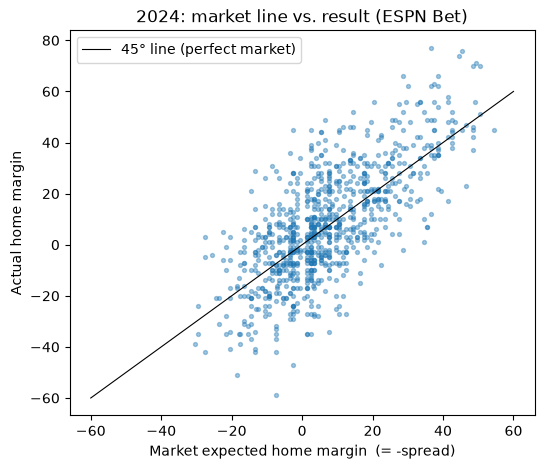

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
espn = scored[scored["provider"] == "ESPN Bet"]
ax.scatter(-espn["spread"], espn["margin"], s=8, alpha=0.4)
lims = [-60, 60]
ax.plot(lims, lims, color="black", linewidth=0.8, label="45° line (perfect market)")
ax.set_xlabel("Market expected home margin  (= -spread)")
ax.set_ylabel("Actual home margin")
ax.set_title(f"{SEASON}: market line vs. result (ESPN Bet)")
ax.legend()
plt.show()

**What matters here: the sign convention**

- In every row, a **negative `spread` means the home team is favored** (`formattedSpread`
  names the home team), and a positive `spread` means the away team is favored. The single
  `0` is a pick'em.
- The regression agrees: margin on `spread` has a **slope of about −1.0 for every
  provider**, with a small intercept (about 1 point). The market is roughly unbiased, and
  the minus sign is the sportsbook convention.
- **Our convention** (CLAUDE.md) is expected home margin, with home favored by 7 written as
  `+7.0`. So in `clean.py`:

  ```python
  # CFBD/sportsbook spread is negative when home is favored; ours is expected home margin.
  market_spread = -lines["spread"]
  ```

  The scatter above is already drawn this way: points line up along the 45° line.
- **First benchmark number:** the closing line misses the actual margin by about
  **12 points** on average (MAE). Our spread models will be scored against that on the
  same games. A model near 12.5–13 would already be respectable.

## 8. Joining lines to games

In [22]:
print("Games:", len(games))
print("Games with at least one line:", games["id"].isin(lines["id"]).sum())
print("Line rows for games NOT in our games table:", (~lines["id"].isin(games["id"])).sum())

# Which classifications are those extra games?
lines.loc[~lines["id"].isin(games["id"]), ["homeClassification", "awayClassification"]].value_counts()

Games: 920
Games with at least one line: 904
Line rows for games NOT in our games table: 655


homeClassification  awayClassification
fcs                 fcs                   655
Name: count, dtype: int64

In [23]:
# Our games that have no line at all
no_line = games[~games["id"].isin(lines["id"])]
no_line[["week", "homeTeam", "awayTeam", "awayClassification", "completed"]]

,week,homeTeam,awayTeam,awayClassification,completed
6,1,Wake Forest,North Carolina A&T,fcs,True
25,1,Army,Lehigh,fcs,True
31,1,Utah State,Robert Morris,fcs,True
37,1,Iowa,Illinois State,fcs,True
64,1,Virginia,Richmond,fcs,True
68,1,Arkansas State,Central Arkansas,fcs,True
70,1,Middle Tennessee,Tennessee Tech,fcs,True
74,1,South Florida,Bethune-Cookman,fcs,True
82,1,Oregon,Idaho,fcs,True
86,1,SMU,Houston Christian,fcs,True


In [24]:
# Do the two endpoints agree on who is home? (They should; same CFBD game id.)
check = lines.merge(games[["id", "homeTeam"]], on="id", suffixes=("", "_games"))
print("Rows where home team differs:", (check["homeTeam"] != check["homeTeam_games"]).sum())

Rows where home team differs: 0


**What matters here**

- **Join on `id`.** It's the same CFBD game id in both tables, and the home team always
  matches, so the sign convention carries over cleanly.
- The lines endpoint returns **extra FCS-vs-FCS games** that aren't in our FBS games pull.
  They drop out in the join, which is what we want.
- **16 of our games have no line**: 15 FBS-vs-FCS mismatches the books didn't post, plus
  the cancelled App State–Liberty game. The market benchmark will cover slightly fewer
  games than the model. Always compare model and market on **the same set of games**.

## 9. Summary: decisions for `clean.py`

| Topic | Finding | Decision |
| --- | --- | --- |
| Column names | camelCase from the API | Rename to snake_case (`home_team`, `away_points`, ...) |
| Leaky columns | Line scores, postgame win prob / Elo, excitement, attendance | Drop them from the clean table |
| Incomplete games | 1 cancelled game, no score | Drop rows that aren't `completed` |
| Dates | ISO strings with UTC offset | Parse to timezone-aware UTC; sort by `start_date`, not `week` (postseason is all week 1) |
| Neutral sites | 80 games; CFP first round is *not* neutral; a few "neutral" games are really home games | Keep CFBD home team, keep the flag, set HFA = 0 when neutral |
| FCS | 121 games, 96 teams, 1–2 games each, always away | Map every FCS team to `"FCS"` |
| Target | `margin = home_points - away_points`; no ties | Add `margin` and `home_win` |
| Spread sign | CFBD `spread` < 0 means home favored (slope of margin on spread ≈ −1) | `market_spread = -spread` (expected home margin) |
| Providers | ESPN Bet ~all games; DraftKings/Bovada about half | One consensus line per game (mean of available closing spreads) |
| Coverage | 16 games have no line | Score model and market on the same games |
| CFBD Elo | Missing for FCS; it's another model | Comparison only, not a feature |

**Market benchmark to beat (2024): closing-line MAE of about 12.0 points.**